# Baseline economics before model complexity

Does positive ML performance establish an incremental allocation advantage?

This notebook reviews saved retrospective evidence. New descriptive calculations are post-study analysis, not new strategy selection or an untouched test.

In [1]:
from pathlib import Path
import json,sys,math,statistics
r=Path.cwd()
if not (r/'artifacts/research').exists(): r=r.parent
sys.path.insert(0,str(r/'src'));sys.path.insert(0,str(r))
from scripts.review_visuals import table,figure,lines,bars
if 'display_bundle' not in globals():
 from IPython.display import display
 def display_bundle(data): display(data,raw=True)
b=json.loads((r/'artifacts/research/public_bundle.json').read_text());a=b['analysis']
p=json.loads((r/'artifacts/review/polish.json').read_text());chosen=b['selected']
print('Saved test:',b['as_of'],'Selected:',chosen,'Post-study review:',p['review_date'])

Saved test: 2025-12-31 Selected: stumps_24 Post-study review: 2026-11-25


## Costed primary comparison

All paths share starting capital and the cash/action engine.

In [2]:
display_bundle(table(['Policy','CAGR','Sharpe (cash=0)','Maximum drawdown'],[[n,f'{v["metrics"]["cagr"]:.2%}',f'{v["metrics"]["sharpe_zero_cash"]:.3f}',f'{v["metrics"]["max_drawdown"]:.2%}'] for n,v in b['results'].items()]))

Policy,CAGR,Sharpe (cash=0),Maximum drawdown
equal_weight,14.16%,1.088,-15.59%
momentum_63,13.19%,0.936,-16.63%
inverse_vol,12.37%,1.006,-15.30%
stumps_24,12.41%,0.785,-19.94%
SPY_buy_hold,22.39%,1.418,-18.31%


## Common-capital paths

Include the initial $100,000. Baselines have different diversification by design.

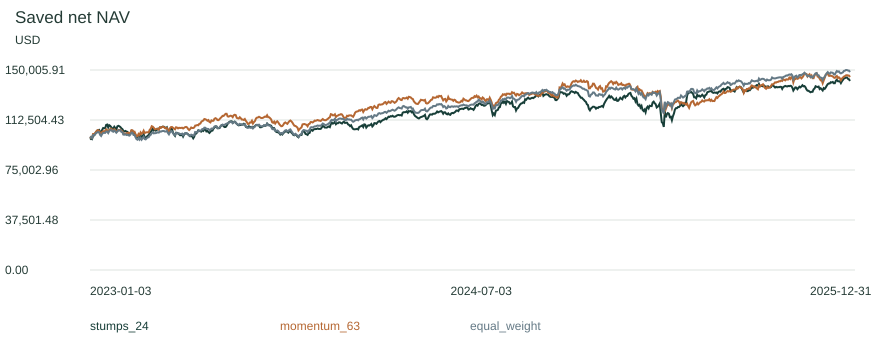

In [3]:
display_bundle(figure(lines('Saved net NAV',[x['date'] for x in b['results'][chosen]['ledger']],{n:[x['nav'] for x in b['results'][n]['ledger']] for n in [chosen,'momentum_63','equal_weight']},'USD')))

## Annual slices

Calendar years are descriptive slices of the same consumed test.

In [4]:
display_bundle(table(['Policy','2023','2024','2025'],[[n]+[f'{x["annual_returns"][y]:.2%}' for y in ['2023','2024','2025']] for n,x in a['strategies'].items()]))

Policy,2023,2024,2025
equal_weight,13.29%,15.56%,13.39%
momentum_63,16.63%,16.81%,6.26%
inverse_vol,10.57%,14.76%,11.63%
stumps_24,9.86%,10.84%,16.44%
SPY_buy_hold,25.31%,24.45%,17.19%


## Interpretation

ML has positive absolute returns but lower primary CAGR and Sharpe than momentum/equal weight. These observations support retaining a negative comparative finding, not searching the test for another winning model.